# OrCaScore — CT com e sem contraste e calcificações de referência

Visualização de duas aquisições do mesmo paciente: **CTAI** com contraste e
**CTI** sem contraste. O exemplo padrão é **TRV1P3**, que possui calcificações
anotadas. TRV1P1, usado anteriormente, possui uma referência válida toda zerada.

- MIPs axiais e fatias centrais das duas aquisições, em células separadas.
- CT sem contraste, rótulos de calcificação e sobreposição, lado a lado e também
  em figuras independentes, com recorte da região anotada.
- Superfície 3D opcional das calcificações de referência.

A orientação dos arquivos é preservada, **sem rotação, flip ou alinhamento ao
ImageCAS**. As aquisições CTAI e CTI não são registradas entre si. Os rótulos
pertencem à CTI e **não são sobrepostos à CTAI**.

A [documentação oficial do OrCaScore](https://orcascore.grand-challenge.org/Data/)
define 1 = LAD (inclui calcificações do tronco esquerdo), 2 = LCX e 3 = RCA.
São rótulos de calcificações atribuídas a cada artéria, não máscaras das artérias
completas. Neste banco local, os rótulos de referência estão no treino.

**Impressão:** PNG e TIFF LZW sem perdas a 600 dpi e PDF. As figuras independentes
usam 90 × 90 mm, sem títulos ou eixos. O DPI não aumenta a resolução anatômica
original. A configuração informa o diretório permanente de exportação.
Não é necessário executar segmentação ou usar GPU.

In [1]:
# ruff: noqa: E402
import json
import os
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch

REPO_ROOT = next(
    path
    for path in (Path.cwd(), *Path.cwd().parents)
    if (path / "pyproject.toml").is_file() and (path / "src").is_dir()
)
if str(REPO_ROOT / "src") not in sys.path:
    sys.path.insert(0, str(REPO_ROOT / "src"))

from utils.project.datasets.ccta import (
    discover_orcascore_acquisitions,
    load_ccta_volume,
    read_mhd_header,
)
from utils.project.runtime.notebook_env import resolve_existing_path
from utils.visualization.images.hu_threshold import hu_axial_mip
from utils.project.datasets.orcascore import (
    ORCASCORE_CALCIFICATION_LABEL_SPECS,
    load_orcascore_calcification_reference,
    orcascore_calcification_reference_path,
)
from utils.utils.roi import mask_bounding_box_slices

## Configuração

Altere `EXAM_ID` e `SUBSET` para outro par. O diretório pode ser definido por
`ORCASCORE_BASE_PATH` ou descoberto nos discos montados. A janela HU é comum às
duas aquisições e às sobreposições. `OUTPUT_ROOT` é o destino das exportações;
`ORCASCORE_FIGURES_ROOT` permite configurá-lo no ambiente.

Na seção de calcificação, o padrão escolhe a fatia **com maior área anotada**,
para tornar a referência visível. `CALCIFICATION_SLICE_INDEX` permite escolher
um índice axial nativo, começando em zero. `CALCIFICATION_MARGIN_MM` define a
margem do recorte em torno das calcificações. Essa seção não representa a fatia
central do volume, que continua disponível nas células anteriores.

In [2]:
# Para outro disco, exporte ORCASCORE_BASE_PATH antes de abrir o kernel.
# Sem variável, procura somente a estrutura conhecida nos discos montados.
MOUNT_ROOTS = (Path("/run/media"), Path("/media"), Path("/mnt"))
DATASET_CANDIDATES = sorted(
    {
        candidate
        for root in MOUNT_ROOTS
        for pattern in (
            "*/*/DatasetsCCTA/Orca_Score_Calcium",
            "*/DatasetsCCTA/Orca_Score_Calcium",
        )
        for candidate in root.glob(pattern)
        if candidate.is_dir()
    }
)
if not os.environ.get("ORCASCORE_BASE_PATH") and len(DATASET_CANDIDATES) > 1:
    raise ValueError("Mais de uma cópia do OrCaScore: defina ORCASCORE_BASE_PATH.")
ORCASCORE_PATH = resolve_existing_path(
    "ORCASCORE_BASE_PATH", DATASET_CANDIDATES, "OrCaScore"
)

EXAM_ID = "TRV1P3"
SUBSET = "train"
WINDOW_LEVEL_HU = 200.0
WINDOW_WIDTH_HU = 800.0
FIGURE_WIDTH_MM = 90.0
EXPORT_DPI = 600
PREVIEW_DPI = 120
OUTPUT_ROOT = Path(
    os.environ.get("ORCASCORE_FIGURES_ROOT")
    or REPO_ROOT / "output/figures/orcascore_calcification"
).expanduser()
CALCIFICATION_MARGIN_MM = 10.0
CALCIFICATION_SLICE_INDEX = None
CALCIFICATION_ALPHA = 0.5
SHOW_CALCIFICATION_3D = False

In [3]:
inventory = discover_orcascore_acquisitions(ORCASCORE_PATH)
selected = inventory.loc[
    inventory["exam_id"].eq(EXAM_ID) & inventory["subset"].eq(SUBSET)
].copy()
if len(selected) != 2 or set(selected["acquisition"]) != {"contrast", "noncontrast"}:
    raise ValueError(f"Esperado exatamente um par CTAI/CTI para {SUBSET}/{EXAM_ID}.")
PAIR = {
    acquisition: selected.loc[selected["acquisition"].eq(acquisition)].iloc[0]
    for acquisition in ("contrast", "noncontrast")
}
if WINDOW_WIDTH_HU <= 0 or not np.isfinite([WINDOW_LEVEL_HU, WINDOW_WIDTH_HU]).all():
    raise ValueError("Janela HU inválida.")
if FIGURE_WIDTH_MM <= 0 or EXPORT_DPI <= 0:
    raise ValueError("Tamanho de impressão e DPI devem ser positivos.")
if (
    selected["reported_orientation"].nunique() != 1
    or selected["reported_orientation"].iloc[0] != "RAI"
):
    raise ValueError("Este temporário espera o par OrCaScore na orientação RAI.")
for record in PAIR.values():
    header = read_mhd_header(record["path"])
    transform = np.fromstring(
        header.get("TransformMatrix", "1 0 0 0 1 0 0 0 1"), sep=" "
    )
    if transform.size != 9 or not np.allclose(transform.reshape(3, 3), np.eye(3)):
        raise ValueError("Aquisição oblíqua: revise a orientação antes da figura.")
# Mesmo campo físico quadrado, centrado no FOV de cada aquisição; sem registrar volumes.
COMMON_FOV_MM = max(
    float(record[size]) * float(record[spacing])
    for record in PAIR.values()
    for size, spacing in (("size_x", "spacing_x_mm"), ("size_y", "spacing_y_mm"))
)
OUTPUT_DIR = OUTPUT_ROOT / f"{SUBSET}_{EXAM_ID}"
print(f"Par selecionado: {SUBSET}/{EXAM_ID} | MIP axial do volume completo")
for acquisition, record in PAIR.items():
    print(
        f"{acquisition}: {Path(record['path']).name}; "
        f"{int(record['slice_count'])} fatias; z={record['spacing_z_mm']:.3f} mm"
    )
print(f"Janela comum: WL={WINDOW_LEVEL_HU:g} / WW={WINDOW_WIDTH_HU:g} HU")
print(f"Exportação: {FIGURE_WIDTH_MM:g} mm, {EXPORT_DPI} dpi; {OUTPUT_DIR}")

Par selecionado: train/TRV1P3 | MIP axial do volume completo
contrast: TRV1P3CTAI.mhd; 212 fatias; z=0.625 mm
noncontrast: TRV1P3CTI.mhd; 56 fatias; z=2.500 mm
Janela comum: WL=200 / WW=800 HU
Exportação: 90 mm, 600 dpi; /home/matheus/workspace/coronary-centerline-detection/output/figures/orcascore_calcification/train_TRV1P3


In [4]:
def save_print_figure(fig, stem, metadata):
    """Exporta figura e proveniência no diretório configurado."""
    OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
    for suffix in ("png", "tiff", "pdf"):
        path = OUTPUT_DIR / f"{stem}.{suffix}"
        options = (
            {"pil_kwargs": {"compression": "tiff_lzw"}} if suffix == "tiff" else {}
        )
        fig.savefig(
            path,
            dpi=EXPORT_DPI,
            facecolor="black",
            edgecolor="black",
            bbox_inches=None,
            pad_inches=0,
            **options,
        )
        print(path)
    (OUTPUT_DIR / f"{stem}.json").write_text(
        json.dumps(metadata, indent=2, ensure_ascii=False), encoding="utf-8"
    )


def export_axial_image(acquisition, mode):
    """Mostra e exporta MIP ou fatia central sem transformar o volume."""
    record = PAIR[acquisition]
    volume = load_ccta_volume(record)
    if mode == "mip":
        slice_index = None
        projection = hu_axial_mip(volume)
        image_suffix = "axial_mip"
    elif mode == "central_slice":
        slice_index = volume.shape[2] // 2
        projection = volume[:, :, slice_index].copy()
        image_suffix = f"axial_central_slice_z{slice_index:04d}"
    else:
        raise ValueError("mode deve ser 'mip' ou 'central_slice'.")
    del volume
    sx, sy = float(record["spacing_x_mm"]), float(record["spacing_y_mm"])
    nx, ny = projection.shape
    # Eixos nativos do volume: eixo 0 vertical, eixo 1 horizontal, sem transformações.
    extent = (-ny * sy / 2, ny * sy / 2, -nx * sx / 2, nx * sx / 2)
    half_fov = COMMON_FOV_MM / 2
    lower = WINDOW_LEVEL_HU - WINDOW_WIDTH_HU / 2
    upper = WINDOW_LEVEL_HU + WINDOW_WIDTH_HU / 2
    OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
    stem = f"orcascore_{SUBSET}_{EXAM_ID}_{acquisition}_{image_suffix}"
    with plt.rc_context({"savefig.facecolor": "black", "savefig.edgecolor": "black"}):
        width_inches = FIGURE_WIDTH_MM / 25.4
        fig = plt.figure(
            figsize=(width_inches, width_inches), dpi=PREVIEW_DPI, facecolor="black"
        )
        ax = fig.add_axes([0, 0, 1, 1], facecolor="black")
        ax.imshow(
            projection,
            cmap="gray",
            origin="upper",
            extent=extent,
            vmin=lower,
            vmax=upper,
            interpolation="nearest",
            aspect="equal",
        )
        ax.set(xlim=(-half_fov, half_fov), ylim=(-half_fov, half_fov))
        ax.set_axis_off()
        plt.show()
        plt.close(fig)
    metadata = {
        "exam_id": EXAM_ID,
        "subset": SUBSET,
        "acquisition": acquisition,
        "source_path": str(record["path"]),
        "view": "axial",
        "projection": "maximum_full_volume" if mode == "mip" else None,
        "image_type": mode,
        "slice_index_zero_based": slice_index,
        "flipped_axes": [],
        "native_shape_xyz": [
            int(record["size_x"]),
            int(record["size_y"]),
            int(record["slice_count"]),
        ],
        "spacing_xyz_mm": [float(record[f"spacing_{axis}_mm"]) for axis in "xyz"],
        "common_fov_mm": COMMON_FOV_MM,
        "centered_fov": True,
        "registered": False,
        "rotation_clockwise_degrees": 0,
        "window_level_hu": WINDOW_LEVEL_HU,
        "window_width_hu": WINDOW_WIDTH_HU,
        "figure_width_mm": FIGURE_WIDTH_MM,
        "export_dpi": EXPORT_DPI,
    }
    save_print_figure(fig, stem, metadata)
    if slice_index is not None:
        print(f"Fatia axial central: z={slice_index} (índice começando em zero).")


def export_axial_mip(acquisition):
    """Exporta a projeção máxima axial da aquisição."""
    export_axial_image(acquisition, "mip")


def export_central_axial_slice(acquisition):
    """Exporta a fatia de índice n_z // 2 da aquisição."""
    export_axial_image(acquisition, "central_slice")

## Com contraste — CTAI

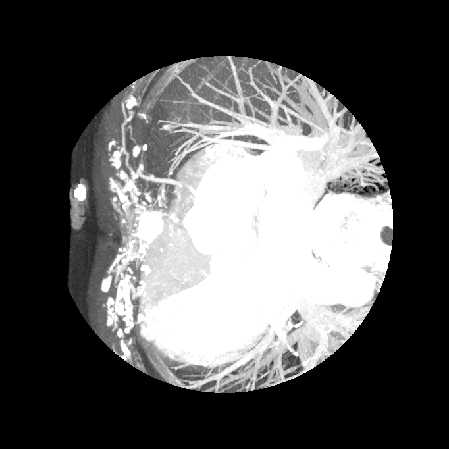

/home/matheus/workspace/coronary-centerline-detection/output/figures/orcascore_calcification/train_TRV1P3/orcascore_train_TRV1P3_contrast_axial_mip.png
/home/matheus/workspace/coronary-centerline-detection/output/figures/orcascore_calcification/train_TRV1P3/orcascore_train_TRV1P3_contrast_axial_mip.tiff
/home/matheus/workspace/coronary-centerline-detection/output/figures/orcascore_calcification/train_TRV1P3/orcascore_train_TRV1P3_contrast_axial_mip.pdf


In [5]:
export_axial_mip("contrast")

## Sem contraste — CTI

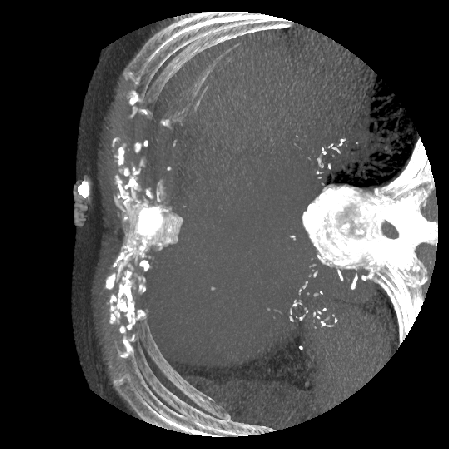

/home/matheus/workspace/coronary-centerline-detection/output/figures/orcascore_calcification/train_TRV1P3/orcascore_train_TRV1P3_noncontrast_axial_mip.png
/home/matheus/workspace/coronary-centerline-detection/output/figures/orcascore_calcification/train_TRV1P3/orcascore_train_TRV1P3_noncontrast_axial_mip.tiff
/home/matheus/workspace/coronary-centerline-detection/output/figures/orcascore_calcification/train_TRV1P3/orcascore_train_TRV1P3_noncontrast_axial_mip.pdf


In [6]:
export_axial_mip("noncontrast")

## Fatias axiais centrais

Cada aquisição usa a fatia de índice **`n_z // 2`**, começando em zero. Para um
número par de fatias, seleciona a segunda das duas centrais. CTAI e CTI têm
coberturas diferentes: os centros não representam necessariamente a mesma
posição anatômica. São mantidas a orientação nativa, a janela HU, a escala física
e a exportação em PNG/TIFF a 600 dpi e PDF.

### Fatia central com contraste — CTAI

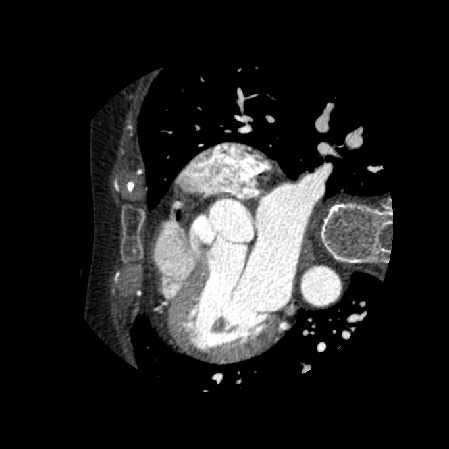

/home/matheus/workspace/coronary-centerline-detection/output/figures/orcascore_calcification/train_TRV1P3/orcascore_train_TRV1P3_contrast_axial_central_slice_z0106.png
/home/matheus/workspace/coronary-centerline-detection/output/figures/orcascore_calcification/train_TRV1P3/orcascore_train_TRV1P3_contrast_axial_central_slice_z0106.tiff
/home/matheus/workspace/coronary-centerline-detection/output/figures/orcascore_calcification/train_TRV1P3/orcascore_train_TRV1P3_contrast_axial_central_slice_z0106.pdf
Fatia axial central: z=106 (índice começando em zero).


In [7]:
export_central_axial_slice("contrast")

### Fatia central sem contraste — CTI

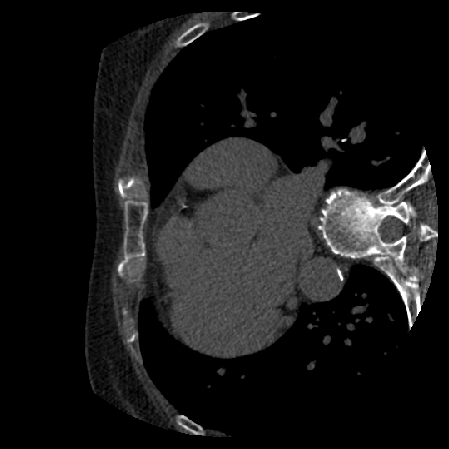

/home/matheus/workspace/coronary-centerline-detection/output/figures/orcascore_calcification/train_TRV1P3/orcascore_train_TRV1P3_noncontrast_axial_central_slice_z0028.png
/home/matheus/workspace/coronary-centerline-detection/output/figures/orcascore_calcification/train_TRV1P3/orcascore_train_TRV1P3_noncontrast_axial_central_slice_z0028.tiff
/home/matheus/workspace/coronary-centerline-detection/output/figures/orcascore_calcification/train_TRV1P3/orcascore_train_TRV1P3_noncontrast_axial_central_slice_z0028.pdf
Fatia axial central: z=28 (índice começando em zero).


In [8]:
export_central_axial_slice("noncontrast")

## Calcificações na CT sem contraste — CT, rótulos e sobreposição

A referência `Reference_standard/<EXAM_ID>R.mhd` só é usada após validar a
geometria contra a CTI: dimensões, espaçamento, origem, direção e orientação.
Sem referência, as visualizações acima continuam disponíveis e esta seção
informa a ausência. Uma referência toda zerada é tratada como exame **sem
calcificações anotadas**, sem confundi-la com arquivo ausente.

O recorte usa a caixa das calcificações com margem física. A fatia escolhida
por padrão é a que contém mais voxels anotados. O fundo dos rótulos é
transparente; a sobreposição usa exatamente a mesma fatia e o mesmo recorte
da CTI. Não há limiarização HU ou geração de uma nova segmentação.

In [9]:
CALCIFICATION_REFERENCE_PATH = orcascore_calcification_reference_path(
    PAIR["noncontrast"]
)
calcification_label = load_orcascore_calcification_reference(PAIR["noncontrast"])
CALCIFICATION_AVAILABLE = calcification_label is not None
if not CALCIFICATION_AVAILABLE:
    print(f"Referência de calcificação ausente: {CALCIFICATION_REFERENCE_PATH}")
else:
    noncontrast_image = load_ccta_volume(PAIR["noncontrast"])
    spacing_xyz = tuple(
        float(PAIR["noncontrast"][f"spacing_{axis}_mm"]) for axis in "xyz"
    )
    if not 0 <= CALCIFICATION_ALPHA <= 1:
        raise ValueError("CALCIFICATION_ALPHA deve estar entre 0 e 1.")
    if np.any(calcification_label):
        calcification_crop = mask_bounding_box_slices(
            calcification_label > 0, spacing_xyz, CALCIFICATION_MARGIN_MM
        )
        default_z = int(np.argmax(np.count_nonzero(calcification_label, axis=(0, 1))))
    else:
        calcification_crop = tuple(slice(0, size) for size in calcification_label.shape)
        default_z = calcification_label.shape[2] // 2
        print("Referência válida sem calcificações anotadas; exibindo a fatia central.")
    calcification_z = (
        default_z if CALCIFICATION_SLICE_INDEX is None else CALCIFICATION_SLICE_INDEX
    )
    if (
        not isinstance(calcification_z, (int, np.integer))
        or not 0 <= calcification_z < noncontrast_image.shape[2]
    ):
        raise ValueError("CALCIFICATION_SLICE_INDEX deve ser um índice axial válido.")
    xy_slices = calcification_crop[:2]
    calcification_ct_slice = noncontrast_image[*xy_slices, calcification_z].copy()
    calcification_label_slice = calcification_label[*xy_slices, calcification_z].copy()
    calcification_label_crop = calcification_label[calcification_crop]
    print(
        f"Fatia CTI: z={calcification_z} | voxels anotados nesta fatia: {np.count_nonzero(calcification_label_slice)}"
    )
    print(f"Referência: {CALCIFICATION_REFERENCE_PATH}")
    del noncontrast_image

Fatia CTI: z=34 | voxels anotados nesta fatia: 36
Referência: /run/media/matheus/HD/DatasetsCCTA/Orca_Score_Calcium/Training_set/Reference_standard/TRV1P3R.mhd


In [10]:
def show_calcification_view(view="comparison"):
    """Mostra a referência na CTI, com cores fixas por artéria e fundo transparente."""
    if not CALCIFICATION_AVAILABLE:
        print(
            "Visualização indisponível: não há referência de calcificação para este exame."
        )
        return
    if view not in {"comparison", "ct", "label", "overlay"}:
        raise ValueError("Visualização de calcificação desconhecida.")
    colors = [
        "#000000",
        *[f"#{color:06x}" for _, color in ORCASCORE_CALCIFICATION_LABEL_SPECS.values()],
    ]
    label_cmap = ListedColormap(colors)
    label_cmap.set_bad(alpha=0)
    visible = np.ma.masked_equal(calcification_label_slice, 0)
    nx, ny = calcification_ct_slice.shape
    sx, sy = spacing_xyz[:2]
    extent = (-ny * sy / 2, ny * sy / 2, -nx * sx / 2, nx * sx / 2)
    half_fov = max(nx * sx, ny * sy) / 2
    views = ("ct", "label", "overlay") if view == "comparison" else (view,)
    width_inches = FIGURE_WIDTH_MM / 25.4
    fig, axes = plt.subplots(
        1,
        len(views),
        squeeze=False,
        figsize=(
            width_inches * len(views),
            width_inches + (0.45 if view == "comparison" else 0),
        ),
        dpi=PREVIEW_DPI,
        facecolor="black",
    )
    for ax, kind in zip(axes.ravel(), views, strict=True):
        ax.set_facecolor("black")
        if kind != "label":
            ax.imshow(
                calcification_ct_slice,
                cmap="gray",
                origin="upper",
                extent=extent,
                vmin=WINDOW_LEVEL_HU - WINDOW_WIDTH_HU / 2,
                vmax=WINDOW_LEVEL_HU + WINDOW_WIDTH_HU / 2,
                interpolation="nearest",
                aspect="equal",
            )
        if kind != "ct":
            ax.imshow(
                visible,
                cmap=label_cmap,
                vmin=0,
                vmax=3,
                origin="upper",
                extent=extent,
                alpha=CALCIFICATION_ALPHA if kind == "overlay" else 1,
                interpolation="nearest",
                aspect="equal",
            )
        ax.set(xlim=(-half_fov, half_fov), ylim=(-half_fov, half_fov))
        ax.set_axis_off()
        if view == "comparison":
            ax.set_title(
                {
                    "ct": "CT sem contraste",
                    "label": "Calcificações de referência",
                    "overlay": "Sobreposição",
                }[kind],
                color="white",
            )
    if view == "comparison":
        fig.legend(
            handles=[
                Patch(facecolor=f"#{color:06x}", label=f"{value}: {name}")
                for value, (name, color) in ORCASCORE_CALCIFICATION_LABEL_SPECS.items()
            ],
            loc="lower center",
            ncol=3,
            frameon=False,
            labelcolor="white",
        )
        fig.subplots_adjust(left=0.015, right=0.985, bottom=0.16, top=0.88, wspace=0.06)
    else:
        fig.subplots_adjust(left=0, right=1, bottom=0, top=1)
    stem = f"orcascore_{SUBSET}_{EXAM_ID}_calcification_{view}_z{calcification_z:04d}"
    metadata = {
        "exam_id": EXAM_ID,
        "subset": SUBSET,
        "acquisition": "noncontrast",
        "image_path": str(PAIR["noncontrast"]["path"]),
        "reference_path": str(CALCIFICATION_REFERENCE_PATH),
        "view": view,
        "slice_index_zero_based": int(calcification_z),
        "slice_selection": "explicit"
        if CALCIFICATION_SLICE_INDEX is not None
        else "max_label_area"
        if np.any(calcification_label)
        else "volume_center_no_calcifications",
        "crop_slices_xyz": [[s.start, s.stop] for s in calcification_crop],
        "spacing_xyz_mm": list(spacing_xyz),
        "margin_mm": CALCIFICATION_MARGIN_MM,
        "flipped_axes": [],
        "rotation_clockwise_degrees": 0,
        "registered": False,
        "window_level_hu": WINDOW_LEVEL_HU,
        "window_width_hu": WINDOW_WIDTH_HU,
        "alpha": CALCIFICATION_ALPHA,
        "export_dpi": EXPORT_DPI,
        "label_specs": {
            str(value): name
            for value, (name, _) in ORCASCORE_CALCIFICATION_LABEL_SPECS.items()
        },
    }
    save_print_figure(fig, stem, metadata)
    plt.show()
    plt.close(fig)

/home/matheus/workspace/coronary-centerline-detection/output/figures/orcascore_calcification/train_TRV1P3/orcascore_train_TRV1P3_calcification_comparison_z0034.png
/home/matheus/workspace/coronary-centerline-detection/output/figures/orcascore_calcification/train_TRV1P3/orcascore_train_TRV1P3_calcification_comparison_z0034.tiff
/home/matheus/workspace/coronary-centerline-detection/output/figures/orcascore_calcification/train_TRV1P3/orcascore_train_TRV1P3_calcification_comparison_z0034.pdf


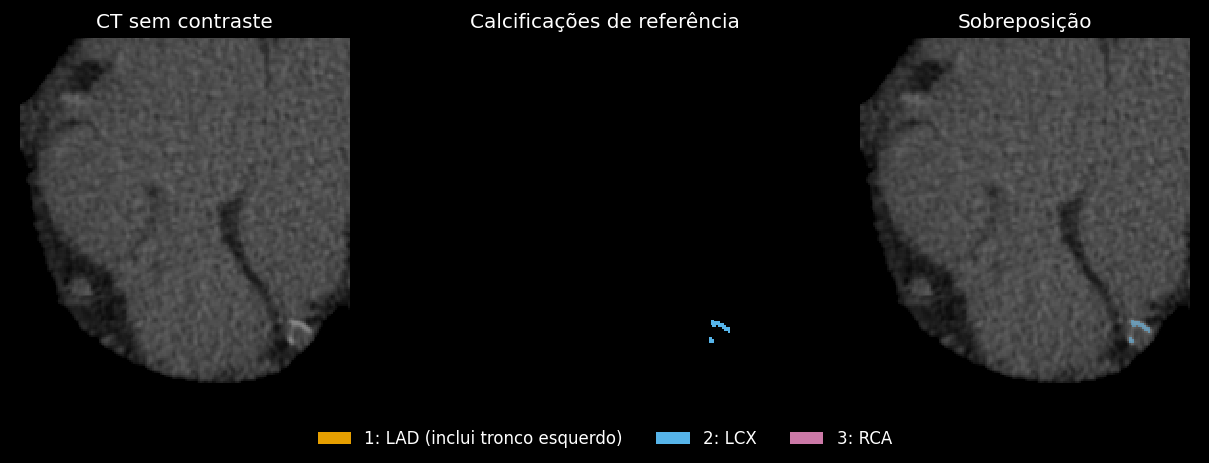

In [11]:
show_calcification_view("comparison")

### CT do recorte — figura independente

/home/matheus/workspace/coronary-centerline-detection/output/figures/orcascore_calcification/train_TRV1P3/orcascore_train_TRV1P3_calcification_ct_z0034.png
/home/matheus/workspace/coronary-centerline-detection/output/figures/orcascore_calcification/train_TRV1P3/orcascore_train_TRV1P3_calcification_ct_z0034.tiff
/home/matheus/workspace/coronary-centerline-detection/output/figures/orcascore_calcification/train_TRV1P3/orcascore_train_TRV1P3_calcification_ct_z0034.pdf


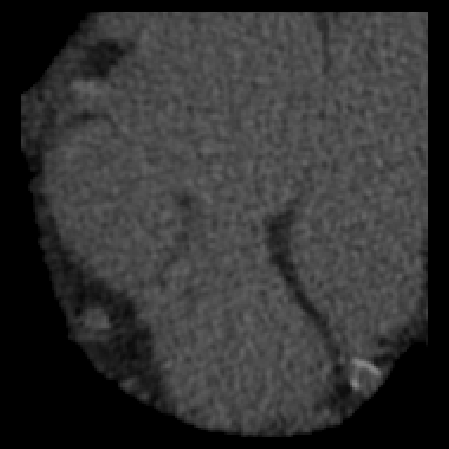

In [12]:
show_calcification_view("ct")

### Rótulos de calcificação — figura independente

/home/matheus/workspace/coronary-centerline-detection/output/figures/orcascore_calcification/train_TRV1P3/orcascore_train_TRV1P3_calcification_label_z0034.png
/home/matheus/workspace/coronary-centerline-detection/output/figures/orcascore_calcification/train_TRV1P3/orcascore_train_TRV1P3_calcification_label_z0034.tiff
/home/matheus/workspace/coronary-centerline-detection/output/figures/orcascore_calcification/train_TRV1P3/orcascore_train_TRV1P3_calcification_label_z0034.pdf


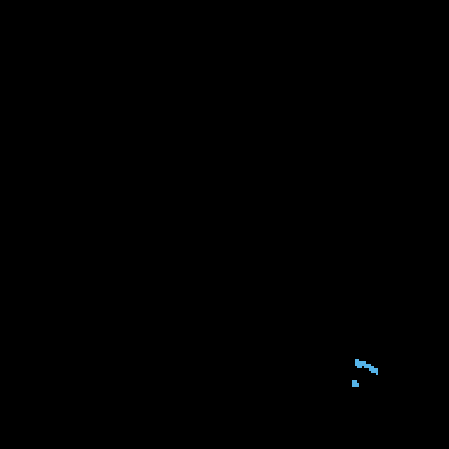

In [13]:
show_calcification_view("label")

### Sobreposição — figura independente

/home/matheus/workspace/coronary-centerline-detection/output/figures/orcascore_calcification/train_TRV1P3/orcascore_train_TRV1P3_calcification_overlay_z0034.png
/home/matheus/workspace/coronary-centerline-detection/output/figures/orcascore_calcification/train_TRV1P3/orcascore_train_TRV1P3_calcification_overlay_z0034.tiff
/home/matheus/workspace/coronary-centerline-detection/output/figures/orcascore_calcification/train_TRV1P3/orcascore_train_TRV1P3_calcification_overlay_z0034.pdf


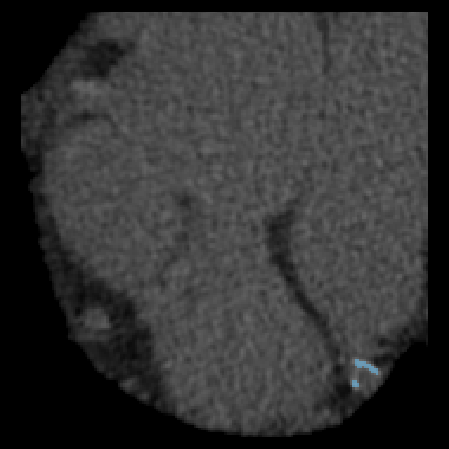

In [14]:
show_calcification_view("overlay")

### Superfície 3D opcional

Ative `SHOW_CALCIFICATION_3D` na configuração. A cena representa somente os
rótulos de referência na CTI, sem reorientação ou suavização das máscaras.

In [15]:
if SHOW_CALCIFICATION_3D and CALCIFICATION_AVAILABLE:
    if np.any(calcification_label_crop):
        from IPython.display import display
        from utils.visualization.images.volume import visualize_label_map_3d

        calcification_plot = visualize_label_map_3d(
            calcification_label_crop,
            ORCASCORE_CALCIFICATION_LABEL_SPECS,
            spacing=spacing_xyz,
            opacity=0.9,
            display_plot=False,
            plot_name=f"OrCaScore {EXAM_ID}: calcificações de referência na CTI",
        )
        display(calcification_plot)
    else:
        print("Referência sem calcificações: não há superfície 3D para exibir.")